# E101: Binned-spectrum fingerprint MLP


In [1]:
import os
from getpass import getpass

# None reuses the environment value or asks through a hidden prompt.
# Never save a literal token in this notebook.
ENV_VALUES = {
    # "KAGGLE_API_TOKEN": None,  # Enable a hidden prompt only if a download is needed.
    # "CASMI_PROJECT": "/content/drive/MyDrive/Data266/EnvedaGroupProject",
}

def inject_environment(values):
    for name, value in values.items():
        if value is None:
            value = os.environ.get(name) or getpass(f"{name}: ")
        os.environ[name] = str(value)

inject_environment(ENV_VALUES)


In [2]:
from pathlib import Path
import os
DRIVE_MOUNT = Path(os.environ.get('CASMI_DRIVE_MOUNT', '/content/drive'))
PROJECT = Path(os.environ.get('CASMI_PROJECT', str(DRIVE_MOUNT / 'MyDrive/Data266/EnvedaGroupProject')))
REPO = PROJECT / 'repo'
TRAIN = REPO / 'data/raw/train.parquet'
OUTPUT = Path(os.environ.get('CASMI_OUTPUT', str(PROJECT / 'cyril')))
STAGE = os.environ.get('CASMI_STAGE', 'final')
resume_setting = os.environ.get('CASMI_RESUME', 'auto').lower()
assert resume_setting in ('auto', 'true', 'false', '1', '0')
RESUME = None if resume_setting == 'auto' else resume_setting in ('true', '1')
SAMPLES = {'smoke': 2000, 'debug': 200_000, 'final': None}
EPOCHS = {'smoke': 2, 'debug': 3, 'final': 30}
assert STAGE in SAMPLES
MODEL_CONFIG = dict(batch_size=256, lr=0.001, patience=3, seed=0)
print('Stage:', STAGE, '| sample:', SAMPLES[STAGE], '| maximum epochs:', EPOCHS[STAGE])
print('Resume:', resume_setting, '| output:', OUTPUT / STAGE)


Stage: final | sample: None | maximum epochs: 30
Resume: auto | output: /content/drive/MyDrive/Data266/EnvedaGroupProject/cyril/final


In [3]:
from google.colab import drive
drive.mount(str(DRIVE_MOUNT))
import os, sys, subprocess, hashlib, tempfile
# /content/drive is the mounted Google Drive filesystem, not local runtime storage.
for path in (PROJECT, REPO, TRAIN, OUTPUT):
    assert DRIVE_MOUNT.resolve() in path.resolve().parents, f'Use a Drive-backed path: {path}'
assert (REPO / 'members/mrcyrilgoud/model_mlp.py').is_file(), 'Missing project code in Drive.'

def source_snapshot(root):
    return {str(p.relative_to(root)): hashlib.sha256(p.read_bytes()).hexdigest()
            for folder in ('src', 'members/mrcyrilgoud')
            for p in (root / folder).rglob('*.py')}

current_source = source_snapshot(REPO)
if '_CYRIL_SOURCE_SNAPSHOT' in globals() and current_source != _CYRIL_SOURCE_SNAPSHOT:
    raise RuntimeError('Source changed. Restart the Colab runtime, then run from the first cell.')
_CYRIL_SOURCE_SNAPSHOT = current_source
# The shared evaluator reads this canonical location relative to REPO.
assert TRAIN.resolve() == (REPO / 'data/raw/train.parquet').resolve()
os.chdir(REPO)
sys.path.insert(0, str(REPO))
# Keep writable package caches, temporary files, bytecode and figures on Drive too.
RUNTIME_FILES = OUTPUT / 'runtime'
for name in ('tmp', 'pip', 'matplotlib', 'torch', 'xdg', 'kagglehub'):
    (RUNTIME_FILES / name).mkdir(parents=True, exist_ok=True)
os.environ.update(TMPDIR=str(RUNTIME_FILES / 'tmp'),
    PIP_CACHE_DIR=str(RUNTIME_FILES / 'pip'), MPLCONFIGDIR=str(RUNTIME_FILES / 'matplotlib'),
    TORCH_HOME=str(RUNTIME_FILES / 'torch'), XDG_CACHE_HOME=str(RUNTIME_FILES / 'xdg'),
    KAGGLEHUB_CACHE=str(RUNTIME_FILES / 'kagglehub'))
tempfile.tempdir = str(RUNTIME_FILES / 'tmp')
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'rdkit', 'pyarrow', 'matplotlib'])
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '--upgrade', 'kagglehub'])
# No API credentials are stored in the notebook, repo, or shared Drive folder.
from members.mrcyrilgoud.kaggle_data import ensure_competition_data

print(f'Download destination: {TRAIN.parent} (mounted Google Drive)')
competition_files = ensure_competition_data(TRAIN.parent)
for name, path in competition_files.items():
    print(name, f'{path.stat().st_size / 1e9:.3f} GB', path)
import torch, rdkit, pyarrow, numpy, pandas, platform
assert torch.cuda.is_available(), 'Select a GPU Colab kernel in Cursor before training.'
print(torch.cuda.get_device_name(), 'torch', torch.__version__, 'rdkit', rdkit.__version__)
from members.mrcyrilgoud.model_mlp import (prepare_cache, train_model, FingerprintMLP,
    evaluate_saved, plot_training, evaluate_blends, package_weights, export_handoff, file_hash, save_json)
from members.mrcyrilgoud.baseline_audit import audit_baseline, final_training_check
from src.data.build_reference import build
from src.models.base import CosineScorer
from src.evaluation.validate import evaluate
RUNS = OUTPUT / STAGE
CACHE = OUTPUT / 'cache' / STAGE
REF = OUTPUT / 'reference'
print('Working repository:', REPO)
print('Persistent outputs:', OUTPUT)
OUTPUT.mkdir(parents=True, exist_ok=True)
# Record the full environment and loaded Python sources before any training.
from datetime import datetime, timezone
ENVIRONMENT = dict(
    recorded_at=datetime.now(timezone.utc).isoformat(), python=platform.python_version(),
    torch=str(torch.__version__), cuda=torch.version.cuda, rdkit=rdkit.__version__,
    numpy=numpy.__version__, pandas=pandas.__version__, pyarrow=pyarrow.__version__,
    gpu=torch.cuda.get_device_name(), source_sha256=current_source)


Mounted at /content/drive
Download destination: /content/drive/MyDrive/Data266/EnvedaGroupProject/repo/data/raw (mounted Google Drive)
Data destination: /content/drive/.shortcut-targets-by-id/1FJlLSN32ryUyC6ZQXJP536d-rLQt5Fsm/Data266/EnvedaGroupProject/repo/data/raw (Google Drive mount)
Transfer direction: Kaggle -> destination filesystem; no browser upload to Colab.
Reusing all three validated competition files in Drive.
train.parquet 3.033 GB /content/drive/.shortcut-targets-by-id/1FJlLSN32ryUyC6ZQXJP536d-rLQt5Fsm/Data266/EnvedaGroupProject/repo/data/raw/train.parquet
test.parquet 0.005 GB /content/drive/.shortcut-targets-by-id/1FJlLSN32ryUyC6ZQXJP536d-rLQt5Fsm/Data266/EnvedaGroupProject/repo/data/raw/test.parquet
sample_submission.csv 0.000 GB /content/drive/.shortcut-targets-by-id/1FJlLSN32ryUyC6ZQXJP536d-rLQt5Fsm/Data266/EnvedaGroupProject/repo/data/raw/sample_submission.csv
Tesla T4 torch 2.14.1+cu130 rdkit 2026.09.2
Working repository: /content/drive/MyDrive/Data266/EnvedaGroupP

In [4]:
save_json(RUNS / 'environment.json', dict(ENVIRONMENT, stage=STAGE, sample=SAMPLES[STAGE],
    max_epochs=EPOCHS[STAGE], model_config=MODEL_CONFIG))
# Bind the persistent reference to this parquet and shared preprocessing source.
reference_settings = {'train_sha256': file_hash(TRAIN),
    'builder_sha256': file_hash(REPO / 'src/data/build_reference.py'),
    'cleaner_sha256': file_hash(REPO / 'src/data/spectra.py')}
import json
marker = REF / 'source.json'
if marker.exists():
    assert json.loads(marker.read_text()) == reference_settings, 'Reference changed; select a new REF directory.'
    assert all((REF / n).is_file() for n in ['ref_meta.parquet', 'ref_peaks.npz', 'structures.parquet'])
else:
    build(str(TRAIN), str(REF))
    save_json(marker, reference_settings)
# Audit both baseline ranking paths on the same data; refresh the evaluator cache.
audit = audit_baseline(TRAIN, REF, RUNS / 'baseline_audit',
    train_sha256=reference_settings['train_sha256'])
baseline = evaluate_saved(CosineScorer(), RUNS / 'baseline', ref_dir=str(REF))
assert abs(baseline['mrr'] - audit['shared']['mrr']) < 1e-12
# All model comparisons use this measured shared baseline, not the historical number.


Baseline audit: loading validation and reference...
Baseline audit: verifying data and reference identities...
Shared cosine MRR@25: 0.891360; original ranking: 0.891360; changed molecules: 0
Ranking policy comparison measured; the remaining historical difference is not established without the original environment/reference.
[library-cosine] MRR@25 = 0.8914 | top-1 0.836 | top-10 0.976 | top-25 0.992 | 250 molecules | 0s


In [5]:
manifest = prepare_cache(TRAIN, CACHE, sample=SAMPLES[STAGE], seed=0)
final_training_check(manifest, STAGE)
print('Shared split:', manifest['split_id'])


final: 699,550 training rows, 36,766 early-stopping rows, 267,026 structures
Shared split: 325f6fd7d6d3eda2f89b61af80c3caf47381a6a651c1f5d121728d57d90a2d59


Training E101: final | resume: False
epoch 1: train=0.07848, val=0.07345
epoch 2: train=0.07289, val=0.07139
epoch 3: train=0.07134, val=0.07021
epoch 4: train=0.07033, val=0.06951
epoch 5: train=0.06962, val=0.06895
epoch 6: train=0.06911, val=0.06872
epoch 7: train=0.06870, val=0.06850
epoch 8: train=0.06837, val=0.06822
epoch 9: train=0.06811, val=0.06809
epoch 10: train=0.06787, val=0.06782
epoch 11: train=0.06767, val=0.06785
epoch 12: train=0.06749, val=0.06775
epoch 13: train=0.06733, val=0.06769
epoch 14: train=0.06719, val=0.06757
epoch 15: train=0.06707, val=0.06757
epoch 16: train=0.06695, val=0.06753
epoch 17: train=0.06684, val=0.06737
epoch 18: train=0.06675, val=0.06734
epoch 19: train=0.06664, val=0.06734
epoch 20: train=0.06655, val=0.06724
epoch 21: train=0.06647, val=0.06717
epoch 22: train=0.06639, val=0.06722
epoch 23: train=0.06632, val=0.06714
epoch 24: train=0.06626, val=0.06721
epoch 25: train=0.06618, val=0.06698
epoch 26: train=0.06612, val=0.06704
epoch 27: 

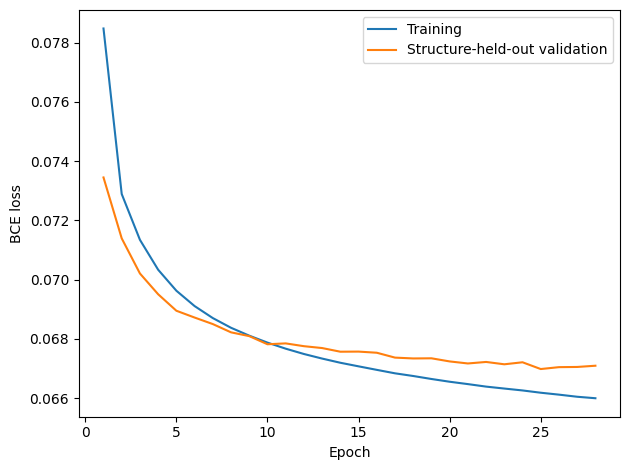

In [6]:
RUN = RUNS / 'E101'
resume_this_run = (RUN / 'last.pt').is_file() if RESUME is None else RESUME
print('Training E101:', STAGE, '| resume:', resume_this_run)
net = train_model(CACHE, RUN, 'spectrum', epochs=EPOCHS[STAGE],
                  resume=resume_this_run, device='cuda', **MODEL_CONFIG)
plot_training(RUN)
del net
torch.cuda.empty_cache()


In [7]:
model = FingerprintMLP(RUN / 'best.pt', device='cpu')
evaluate(model, ref_dir=str(REF), limit=20)
metrics = evaluate_saved(model, RUN / 'evaluation', RUN / 'best.pt', ref_dir=str(REF))
print(metrics)

[fp-mlp-spectrum] MRR@25 = 0.4551 | top-1 0.300 | top-10 0.750 | top-25 1.000 | 20 molecules | 0s
[fp-mlp-spectrum] MRR@25 = 0.4188 | top-1 0.260 | top-10 0.756 | top-25 0.884 | 250 molecules | 1s
{'model': 'fp-mlp-spectrum', 'mrr': np.float64(0.41883574863389106), 'top1': np.float64(0.26), 'top10': np.float64(0.756), 'top25': np.float64(0.884), 'evaluation_protocol': {'reference': {'source_manifest': '8eb3377205c4c7c0aa9c4908c5358ed62ecf6fa6da34d6dc95949eeb7f10db89'}, 'ppm': 15, 'hide_true': False, 'limit': None, 'k': 25, 'molecules_sha256': '829b9d982c9aa4950aaec5a8a726db62ceccdf102197b7d19e85d47682ef8ab5'}, 'checkpoint_sha256': 'f8ae89d5ea96f8879e2300a3508f793b1cd7ef5dc353eb00741ecd0f0d541d10', 'split_id': '325f6fd7d6d3eda2f89b61af80c3caf47381a6a651c1f5d121728d57d90a2d59', 'cache_sha256': '750a1337620b8a2857e8a5ee5c17d94159fb0cdd6889175ef0ad5a27216dd320'}
